# Question 2 : Le montant cumulé suffit-il à mesurer la valeur d'un client ?

Objectif : vérifier si classer les clients uniquement sur `montant_total_eur` est fiable, ou si cet indicateur mélange des profils très différents et produit des erreurs de classement.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")

# Chargement des données propres
df = pd.read_csv("../data/clean/clients_clean.csv")
print("Colonnes du fichier :", df.columns.tolist())
display(df.head(3))


Colonnes du fichier : ['client_id', 'boutique_principale', 'anciennete_mois', 'nb_achats_12m', 'panier_moyen_eur', 'retours', 'demandes_sav', 'carte_fidelite', 'canal_prefere', 'pays_residence', 'montant_prochain_achat_eur', 'est_revenu_6m', 'montant_total_eur', 'ville', 'surface_m2', 'vendeurs', 'ouverte_depuis_mois', 'pays_boutique']


,client_id,boutique_principale,anciennete_mois,nb_achats_12m,panier_moyen_eur,retours,demandes_sav,carte_fidelite,canal_prefere,pays_residence,montant_prochain_achat_eur,est_revenu_6m,montant_total_eur,ville,surface_m2,vendeurs,ouverte_depuis_mois,pays_boutique
0,CT80059,BT15,4,4,1468.0,0,0,aucune,en ligne,USA,725.0,oui,5872.0,Séoul,483,8,236,Corée
1,CT80578,BT28,80,3,1235.0,1,1,argent,boutique,France,1479.0,oui,3705.0,Cannes,267,14,182,France
2,CT80256,BT27,43,1,1814.0,0,2,or,boutique,France,2307.0,oui,1814.0,Dubaï,519,12,209,EAU


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid")

# Chargement des données propres
df = pd.read_csv("../data/clean/clients_clean.csv")

# Conversion de est_revenu_6m ("oui"/"non") en variable numérique 1/0
df["revenu_6m_num"] = np.where(df["est_revenu_6m"] == "oui", 1, 0)

# 1. Statistiques et corrélations avec le montant cumulé
cols_num = [
    "montant_total_eur", "panier_moyen_eur", "nb_achats_12m",
    "anciennete_mois", "revenu_6m_num", "retours", "demandes_sav",
    "montant_prochain_achat_eur"
]
display(df[cols_num].describe().round(1))

print("--- Corrélations avec montant_total_eur ---")
print(df[cols_num].corr()["montant_total_eur"].sort_values(ascending=False).round(2))

# 2. Classement actuel : Top 20 % selon montant_total_eur
seuil_top20 = df["montant_total_eur"].quantile(0.80)
df["top20_cumule"] = df["montant_total_eur"] >= seuil_top20
print(f"\nSeuil Top 20 % cumulé : {seuil_top20:.0f} € ({df['top20_cumule'].sum()} clients)")

# 3. Erreurs de classement visibles
# Erreur A ("Faux VIP") : dans le Top 20 % cumulé, mais pas revenus depuis 6 mois
faux_vip = df[df["top20_cumule"] & (df["revenu_6m_num"] == 0)]

# Erreur B ("VIP oubliés") : hors Top 20 % cumulé, mais actifs (revenus < 6 mois), récents (<= 18 mois) et gros panier (top 25 %)
seuil_panier_haut = df["panier_moyen_eur"].quantile(0.75)
vip_oublies = df[(~df["top20_cumule"]) & (df["revenu_6m_num"] == 1) & (df["panier_moyen_eur"] >= seuil_panier_haut) & (df["anciennete_mois"] <= 18)]

print(f"Faux VIP (Top 20 % cumulé mais pas revenus depuis 6 mois) : {len(faux_vip)} / {df['top20_cumule'].sum()} ({len(faux_vip)/df['top20_cumule'].sum()*100:.1f} %)")
print(f"VIP oubliés (récents <= 18m, gros panier >= {seuil_panier_haut:.0f} €, actifs, hors Top 20 %) : {len(vip_oublies)}")

print("\nExemples de Faux VIP :")
display(faux_vip[["client_id", "montant_total_eur", "anciennete_mois", "est_revenu_6m", "nb_achats_12m", "panier_moyen_eur", "carte_fidelite"]].head(5))

print("\nExemples de VIP oubliés :")
display(vip_oublies[["client_id", "montant_total_eur", "anciennete_mois", "est_revenu_6m", "nb_achats_12m", "panier_moyen_eur", "carte_fidelite"]].head(5))


,montant_total_eur,panier_moyen_eur,nb_achats_12m,anciennete_mois,revenu_6m_num,retours,demandes_sav,montant_prochain_achat_eur
count,700.0,700.0,700.0,700.0,700.0,700.0,700.0,700.0
mean,12674.7,2643.2,3.7,30.8,0.4,0.5,0.4,1972.0
std,20522.3,1883.4,2.9,24.3,0.5,0.8,0.6,1135.3
min,290.0,290.0,1.0,1.0,0.0,0.0,0.0,90.0
25%,2909.0,1519.2,2.0,12.0,0.0,0.0,0.0,1254.5
50%,5308.5,2088.0,3.0,23.0,0.0,0.0,0.0,1692.5
75%,9276.8,2926.0,5.0,49.0,1.0,1.0,1.0,2334.2
max,114165.0,12685.0,17.0,116.0,1.0,5.0,3.0,6708.0


--- Corrélations avec montant_total_eur ---
montant_total_eur             1.00
panier_moyen_eur              0.86
nb_achats_12m                 0.84
montant_prochain_achat_eur    0.79
retours                       0.31
revenu_6m_num                 0.17
demandes_sav                 -0.07
anciennete_mois              -0.22
Name: montant_total_eur, dtype: float64

Seuil Top 20 % cumulé : 10884 € (140 clients)
Faux VIP (Top 20 % cumulé mais pas revenus depuis 6 mois) : 62 / 140 (44.3 %)
VIP oubliés (récents <= 18m, gros panier >= 2926 €, actifs, hors Top 20 %) : 18

Exemples de Faux VIP :


,client_id,montant_total_eur,anciennete_mois,est_revenu_6m,nb_achats_12m,panier_moyen_eur,carte_fidelite
20,CT80610,44718.0,16,non,6,7453.0,argent
21,CT80679,63504.0,11,non,9,7056.0,or
23,CT80013,12534.0,23,non,6,2089.0,aucune
51,CT80379,76230.0,3,non,10,7623.0,or
55,CT80235,16216.0,57,non,8,2027.0,aucune



Exemples de VIP oubliés :


,client_id,montant_total_eur,anciennete_mois,est_revenu_6m,nb_achats_12m,panier_moyen_eur,carte_fidelite
18,CT80452,7184.0,17,oui,2,3592.0,aucune
45,CT80496,4372.0,4,oui,1,4372.0,inconnue
94,CT80064,6190.0,13,oui,2,3095.0,aucune
115,CT80138,7064.0,15,oui,2,3532.0,aucune
116,CT80425,6204.0,11,oui,2,3102.0,or


## 2. Segmentation K-Means pour identifier les vrais profils de valeur

Au lieu d'un seul montant cumulé, on regroupe les clients avec **K-Means** (variables centrées-réduites avec `StandardScaler`) sur 4 critères : activité récente (`revenu_6m_num`), fréquence d'achat (`nb_achats_12m`), panier moyen (`panier_moyen_eur`) et ancienneté (`anciennete_mois`).


In [5]:
features = ["revenu_6m_num", "nb_achats_12m", "panier_moyen_eur", "anciennete_mois"]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

# 1. Vérification du nombre de clusters (méthode du coude / inertie)
inerties = []
for k in range(2, 8):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    inerties.append(km.inertia_)

# 2. Entraînement du modèle K-Means à 4 segments
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(X_scaled)

# Résumé moyen de chaque cluster
profils = df.groupby("cluster").agg(
    nb_clients=("client_id", "count"),
    cumul_moyen=("montant_total_eur", "mean"),
    panier_moyen=("panier_moyen_eur", "mean"),
    achats_12m=("nb_achats_12m", "mean"),
    anciennete_mois=("anciennete_mois", "mean"),
    pct_actifs_6m=("revenu_6m_num", "mean"),
    prochain_achat=("montant_prochain_achat_eur", "mean"),
    pct_dans_top20_cumule=("top20_cumule", "mean")
)
profils["part_fichier_pct"] = (profils["nb_clients"] / len(df) * 100).round(1)
profils["pct_actifs_6m"] = (profils["pct_actifs_6m"] * 100).round(1)
profils["pct_dans_top20_cumule"] = (profils["pct_dans_top20_cumule"] * 100).round(1)

display(profils.round(1))


,nb_clients,cumul_moyen,panier_moyen,achats_12m,anciennete_mois,pct_actifs_6m,prochain_achat,pct_dans_top20_cumule,part_fichier_pct
cluster,,,,,,,,,
0,89,61466.8,6681.0,9.5,14.6,62.9,4218.9,100.0,12.7
1,280,5101.8,2152.3,2.4,17.8,0.0,1669.5,7.5,40.0
2,136,6021.3,1680.3,3.5,68.6,27.2,1481.5,10.3,19.4
3,195,5919.7,2176.6,2.9,30.4,100.0,1722.8,8.2,27.9


## 3. Graphiques et conclusion Q2


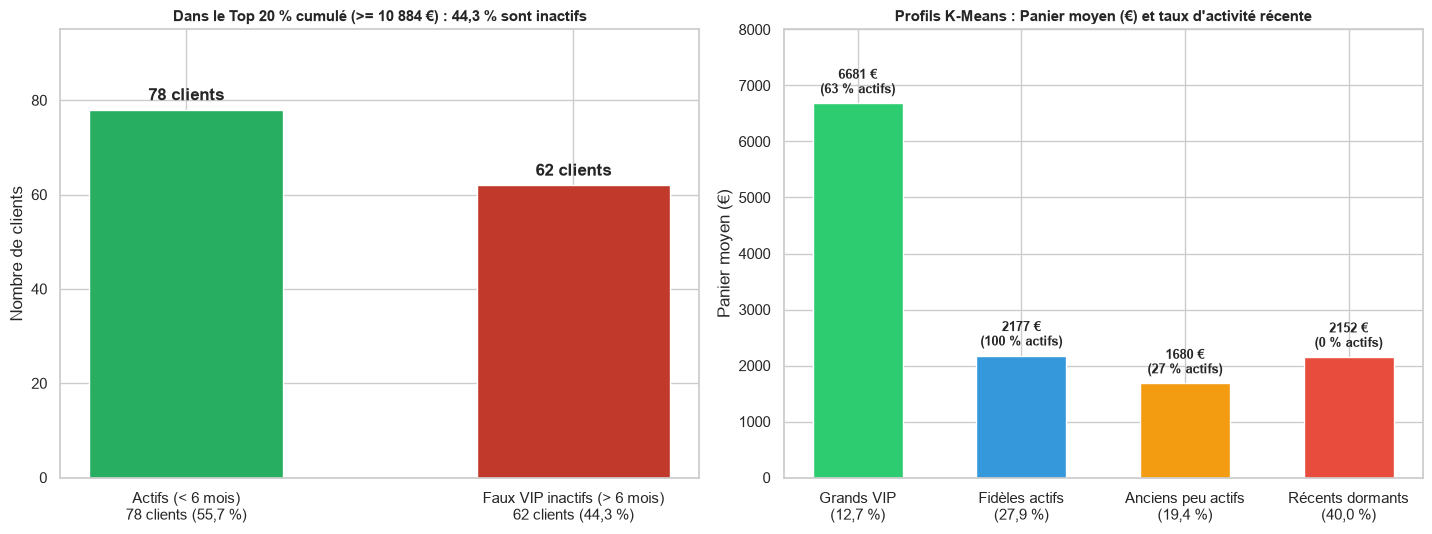

In [6]:
# Attribution des noms métiers aux 4 clusters
noms_clusters = {
    0: "Grands VIP (12,7 %)",
    3: "Fidèles actifs (27,9 %)",
    2: "Anciens peu actifs (19,4 %)",
    1: "Récents dormants (40,0 %)"
}
df["profil_kmeans"] = df["cluster"].map(noms_clusters)

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5))

# Graphique 1 : Composition du Top 20 % cumulé (actifs vs inactifs depuis 6 mois)
repartition_top20 = pd.Series({
    "Actifs (< 6 mois)\n78 clients (55,7 %)": int((df["top20_cumule"] & (df["revenu_6m_num"] == 1)).sum()),
    "Faux VIP inactifs (> 6 mois)\n62 clients (44,3 %)": int((df["top20_cumule"] & (df["revenu_6m_num"] == 0)).sum())
})

bars = axes[0].bar(repartition_top20.index, repartition_top20.values, color=["#27ae60", "#c0392b"], width=0.5)
axes[0].set_ylim(0, 95)
axes[0].set_title("Dans le Top 20 % cumulé (>= 10 884 €) : 44,3 % sont inactifs", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Nombre de clients")
for bar in bars:
    h = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, h + 2, f"{h} clients", ha="center", fontweight="bold")

# Graphique 2 : Les 4 profils K-Means (Panier moyen vs % actifs à 6 mois)
ordre_k = ["Grands VIP (12,7 %)", "Fidèles actifs (27,9 %)", "Anciens peu actifs (19,4 %)", "Récents dormants (40,0 %)"]
resume_k = df.groupby("profil_kmeans").agg(
    panier_moyen=("panier_moyen_eur", "mean"),
    pct_actifs=("revenu_6m_num", lambda x: x.mean() * 100)
).reindex(ordre_k)

x = np.arange(len(ordre_k))
bars2 = axes[1].bar(x, resume_k["panier_moyen"], color=["#2ecc71", "#3498db", "#f39c12", "#e74c3c"], width=0.55)
axes[1].set_ylim(0, 8000)
axes[1].set_title("Profils K-Means : Panier moyen (€) et taux d'activité récente", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Panier moyen (€)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(["Grands VIP\n(12,7 %)", "Fidèles actifs\n(27,9 %)", "Anciens peu actifs\n(19,4 %)", "Récents dormants\n(40,0 %)"])

for bar, actif in zip(bars2, resume_k["pct_actifs"]):
    h = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, h + 180, f"{h:.0f} €\n({actif:.0f} % actifs)", ha="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.savefig("../slides/q2_valeur_client.png", dpi=150, bbox_inches="tight")
plt.show()


### Conclusion Q2

* **Non, le montant cumulé (`montant_total_eur`) ne suffit pas à mesurer la valeur client :** il favorise mécaniquement l'ancienneté et l'historique passé plutôt que l'activité récente (corrélation de 0,17 seulement avec le retour sur 6 mois).
* **Deux erreurs de classement majeures dans le Top 20 % cumulé (>= 10 884 €, 140 clients) :**
  * **44,3 % de « Faux VIP » (62 clients)** sont classés tout en haut grâce à d'anciens achats, alors qu'ils ne sont plus revenus depuis 6 mois.
  * **18 « VIP oubliés »** (récents <= 18 mois, actifs, avec un panier >= 2 926 €) sont exclus du Top 20 % par manque d'ancienneté.
* **La segmentation K-Means (4 profils)** montre que les **Fidèles actifs** (27,9 % du fichier, 100 % revenus sur 6 mois, panier moyen 2 177 €) ont un cumul moyen inférieur aux **Anciens peu actifs** (5 920 € vs 6 021 €), alors qu'ils portent bien plus de valeur future. Il faut remplacer le tri sur le cumul seul par un **score combinant Récence, Fréquence et Panier moyen (RFM)**.
